# EDA NextWatch

Analyse exploratoire des données MovieLens 100k. De plus, les données du jeu de données MovieLens 100k ont été collectées précisément entre le 19 septembre 1997 et le 22 avril 1998.

**Question principale :** selon l'âge et le sexe, quels genres de films sont **proportionnellement les plus notés** ?
(parts de notes par genre — pas les notes moyennes.)
Nous ne mesurons pas ici la note moyenne — c'est-à-dire si un groupe aime ou n'aime pas un film —, mais bien la part de consommation, c'est-à-dire l'intérêt ou le volume d'activité de notation dédié à chaque genre.

1. **Qu'ai-je ?** — structure du jeu
2. **Puis-je faire confiance aux données ?** — qualité, manquants (dont genre `unknown`)
3. **Quels genres sont proportionnellement les plus notés selon l'âge et le sexe ?**
4. **Qu'est-ce qui manque ?** — biais, limites, représentativité, causalité


## Étape 1 — Qu'ai-je ?

Avant d'analyser les tendances, on décrit la structure du jeu de données. Cette étape précise le nombre d'observations, les variables disponibles, leurs types et les premiers ordres de grandeur.

In [21]:
from pathlib import Path

import pandas as pd

# Référentiel des genres (sans "unknown" : traité comme manquant et retiré ci-dessous)
GENRES = [
    "Action", "Adventure", "Animation", "Children's", "Comedy",
    "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western",
]

_candidates = [Path("../dataset"), Path("dataset")]
DATA_DIR = next(
    (p for p in _candidates if p.is_dir() and (p / "u.data.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Dossier dataset introuvable (u.data.csv manquant).")

notes = pd.read_csv(DATA_DIR / "u.data.csv")
films = pd.read_csv(DATA_DIR / "u.item.csv")
users = pd.read_csv(DATA_DIR / "u.user.csv", dtype={"zip_code": "string"})

notes["datetime"] = pd.to_datetime(notes["timestamp"], unit="s", utc=True)
films["release_date"] = pd.to_datetime(
    films["release_date"], format="%d-%b-%Y", errors="coerce"
)
films["release_year"] = films["release_date"].dt.year

df_raw = notes.merge(users, on="user_id", how="left").merge(
    films, left_on="item_id", right_on="movie_id", how="left"
)

# Genre "unknown" = information manquante → documenté puis sorti du jeu d'analyse
n_unknown_notes = int((df_raw["unknown"] == 1).sum())
n_unknown_films = int(films.loc[films["unknown"] == 1, "movie_id"].nunique())
UNKNOWN_MISSING = {
    "type": "genre unknown (non renseigné)",
    "n_films": n_unknown_films,
    "n_notes": n_unknown_notes,
    "pourcentage_notes": round(100 * n_unknown_notes / len(df_raw), 4),
}

df = df_raw.loc[df_raw["unknown"] != 1].drop(columns=["unknown"]).copy()

# Colonnes 0/1 → une colonne liste "genres" (ex. ["Action", "Sci-Fi"])
df["genres"] = df[GENRES].apply(
    lambda row: [g for g in GENRES if row[g] == 1],
    axis=1,
)
df = df.drop(columns=GENRES)

print(
    f"df analysé : {df.shape[0]:,} lignes × {df.shape[1]} colonnes "
    f"(retirées {n_unknown_notes} notes / {n_unknown_films} films à genre unknown)"
)
df.head()


df analysé : 99,990 lignes × 16 colonnes (retirées 10 notes / 2 films à genre unknown)


,user_id,item_id,rating,timestamp,datetime,age,gender,occupation,zip_code,movie_id,title,release_date,video_release_date,imdb_url,release_year,genres
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,49,M,writer,55105,242,Kolya (1996),1997-01-24,NaN,http://us.imdb.com/M/title-exact?Kolya%20(1996),1997.0,[Comedy]
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,39,F,executive,00000,302,L.A. Confidential (1997),1997-01-01,NaN,http://us.imdb.com/M/title-exact?L%2EA%2E+Conf...,1997.0,"[Crime, Film-Noir, Mystery, Thriller]"
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,25,M,writer,40206,377,Heavyweights (1994),1994-01-01,NaN,http://us.imdb.com/M/title-exact?Heavyweights%...,1994.0,"[Children's, Comedy]"
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,28,M,technician,80525,51,Legends of the Fall (1994),1994-01-01,NaN,http://us.imdb.com/M/title-exact?Legends%20of%...,1994.0,"[Drama, Romance, War, Western]"
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,47,M,educator,55113,346,Jackie Brown (1997),1997-01-01,NaN,http://us.imdb.com/M/title-exact?imdb-title-11...,1997.0,"[Crime, Drama]"


Pour garantir la fiabilité de nos analyses, nous avons commencé par auditer la qualité des données.

Concernant les valeurs manquantes, nous avons identifié un cas particulier : le genre de film étiqueté unknown. 
Dans notre dataset, cela représentait seulement 2 films et 10 notes, soit 0,01 % du total. 

Plutôt que de conserver cette catégorie vide de sens pour notre problématique, nous l'avons documentée puis exclue du périmètre d'analyse. Cela nous permet de travailler sur un jeu de données 100 % qualifié sur les genres.


### 1. Aperçu

Le DataFrame `df` a déjà été chargé dans la cellule précédente.
Les genres ne sont plus des colonnes 0/1 : une seule colonne **`genres`** contient une **liste** de genres (ex. `['Action', 'Sci-Fi']`).
On observe ici quelques lignes et un échantillon aléatoire.


**Premières lignes :**


In [22]:
display(df.head())


,user_id,item_id,rating,timestamp,datetime,age,gender,occupation,zip_code,movie_id,title,release_date,video_release_date,imdb_url,release_year,genres
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,49,M,writer,55105,242,Kolya (1996),1997-01-24,NaN,http://us.imdb.com/M/title-exact?Kolya%20(1996),1997.0,[Comedy]
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,39,F,executive,00000,302,L.A. Confidential (1997),1997-01-01,NaN,http://us.imdb.com/M/title-exact?L%2EA%2E+Conf...,1997.0,"[Crime, Film-Noir, Mystery, Thriller]"
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,25,M,writer,40206,377,Heavyweights (1994),1994-01-01,NaN,http://us.imdb.com/M/title-exact?Heavyweights%...,1994.0,"[Children's, Comedy]"
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,28,M,technician,80525,51,Legends of the Fall (1994),1994-01-01,NaN,http://us.imdb.com/M/title-exact?Legends%20of%...,1994.0,"[Drama, Romance, War, Western]"
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,47,M,educator,55113,346,Jackie Brown (1997),1997-01-01,NaN,http://us.imdb.com/M/title-exact?imdb-title-11...,1997.0,"[Crime, Drama]"


**Échantillon aléatoire :**


In [23]:
display(df.sample(5, random_state=42))


,user_id,item_id,rating,timestamp,datetime,age,gender,occupation,zip_code,movie_id,title,release_date,video_release_date,imdb_url,release_year,genres
33972,320,458,4,884748868,1998-01-14 03:34:28+00:00,19,M,student,24060,458,Nixon (1995),1995-01-01,NaN,http://us.imdb.com/M/title-exact?Nixon%20(1995),1995.0,[Drama]
22860,456,200,4,881374390,1997-12-06 02:13:10+00:00,24,M,technician,31820,200,"Shining, The (1980)",1980-01-01,NaN,"http://us.imdb.com/M/title-exact?Shining,%20Th...",1980.0,[Horror]
19455,254,679,2,886472434,1998-02-03 02:20:34+00:00,44,M,educator,42647,679,Conan the Barbarian (1981),1981-01-01,NaN,http://us.imdb.com/M/title-exact?Conan+the+Bar...,1981.0,"[Action, Adventure]"
9736,268,139,2,875744744,1997-10-01 22:25:44+00:00,24,M,engineer,19422,139,"Love Bug, The (1969)",1969-01-01,NaN,"http://us.imdb.com/M/title-exact?Love%20Bug,%2...",1969.0,"[Children's, Comedy]"
7131,332,1013,3,887938798,1998-02-20 01:39:58+00:00,20,M,student,40504,1013,Anaconda (1997),1997-04-11,NaN,http://us.imdb.com/M/title-exact?Anaconda%20%2...,1997.0,"[Action, Adventure, Thriller]"


### 2. Dimensions et variables

`df.shape` indique le nombre de lignes et de colonnes. `df.columns` permet d'identifier les variables disponibles dans la table fusionnée.

In [24]:
print("Dimensions du DataFrame :", df.shape)


Dimensions du DataFrame : (99990, 16)


On peut en deduire quela table contient 99 990 notes d'utilisateurs, et chacune de ces notes est décrite par 33 variables.

**Variables disponibles :**


In [25]:
display(pd.DataFrame({"variable": df.columns}))


,variable
0,user_id
1,item_id
2,rating
3,timestamp
4,datetime
5,age
6,gender
7,occupation
8,zip_code
9,movie_id


### 3. Types et informations générales

`df.info()` et `df.dtypes` permettent de vérifier les types des colonnes et la présence éventuelle de valeurs manquantes.

**Informations générales :**


In [26]:
df.info()


<class 'pandas.DataFrame'>
Index: 99990 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype             
---  ------              --------------  -----             
 0   user_id             99990 non-null  int64             
 1   item_id             99990 non-null  int64             
 2   rating              99990 non-null  int64             
 3   timestamp           99990 non-null  int64             
 4   datetime            99990 non-null  datetime64[s, UTC]
 5   age                 99990 non-null  int64             
 6   gender              99990 non-null  str               
 7   occupation          99990 non-null  str               
 8   zip_code            99990 non-null  string            
 9   movie_id            99990 non-null  int64             
 10  title               99990 non-null  str               
 11  release_date        99990 non-null  datetime64[us]    
 12  video_release_date  0 non-null      float64           
 13  im

**Types des variables :**


In [27]:
display(df.dtypes.rename("type").to_frame())


,type
user_id,int64
item_id,int64
rating,int64
timestamp,int64
datetime,"datetime64[s, UTC]"
age,int64
gender,str
occupation,str
zip_code,string
movie_id,int64


### 4. Premiers ordres de grandeur

`df.describe()` résume les variables numériques avec leur effectif, leur moyenne, leur écart-type, leurs quartiles et leurs valeurs extrêmes.

In [28]:
# Premiers ordres de grandeur sur les variables numériques
description = df.describe().T
display(description)


,count,mean,min,25%,50%,75%,max,std
user_id,99990.0,462.50112,1.0,254.0,447.0,682.0,943.0,266.611967
item_id,99990.0,425.534923,1.0,175.0,322.0,631.0,1682.0,330.797909
rating,99990.0,3.529893,1.0,3.0,4.0,4.0,5.0,1.125656
timestamp,99990.0,883529607.417172,874724710.0,879448759.0,882826983.0,888259984.0,893286638.0,5343579.306067
age,99990.0,32.970407,7.0,24.0,30.0,40.0,73.0,11.562926
movie_id,99990.0,425.534923,1.0,175.0,322.0,631.0,1682.0,330.797909
release_date,99990,1988-02-09 02:12:40.828082,1922-01-01 00:00:00,1986-01-01 00:00:00,1994-01-01 00:00:00,1996-09-28 00:00:00,1998-10-23 00:00:00,NaN
video_release_date,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,99990.0,1987.956386,1922.0,1986.0,1994.0,1996.0,1998.0,14.155492


### 5. Conclusion

Le DataFrame rassemble notes, utilisateurs et films (hors genre `unknown`, retiré au chargement).
On connaît dimensions, variables et types : le cadre de l'analyse est posé.

→ **Étape suivante :** vérifier si l'on peut faire confiance à ces données (manquants, doublons, cohérence).


In [29]:
print(f"Le jeu de données contient {df.shape[0]:,} lignes et {df.shape[1]} colonnes.")


Le jeu de données contient 99,990 lignes et 16 colonnes.


Les notes, utilisateurs et films sont fusionnés dans un même DataFrame d'analyse.


## Étape 2 — Puis-je faire confiance aux données ?

On vérifie manquants (y compris le genre `unknown` déjà filtré), doublons, catégories,
min/max/quantiles, puis la cohérence des dates, unités et types.

→ Objectif : savoir ce qui est fiable avant de répondre à la question principale (étape 3).


### 1. Point de départ

Le DataFrame `df` est déjà chargé (étape 1). On enchaîne directement sur les contrôles de qualité.


In [30]:
print("df déjà en mémoire — dimensions :", df.shape)
df.head()


df déjà en mémoire — dimensions : (99990, 16)


,user_id,item_id,rating,timestamp,datetime,age,gender,occupation,zip_code,movie_id,title,release_date,video_release_date,imdb_url,release_year,genres
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,49,M,writer,55105,242,Kolya (1996),1997-01-24,NaN,http://us.imdb.com/M/title-exact?Kolya%20(1996),1997.0,[Comedy]
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,39,F,executive,00000,302,L.A. Confidential (1997),1997-01-01,NaN,http://us.imdb.com/M/title-exact?L%2EA%2E+Conf...,1997.0,"[Crime, Film-Noir, Mystery, Thriller]"
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,25,M,writer,40206,377,Heavyweights (1994),1994-01-01,NaN,http://us.imdb.com/M/title-exact?Heavyweights%...,1994.0,"[Children's, Comedy]"
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,28,M,technician,80525,51,Legends of the Fall (1994),1994-01-01,NaN,http://us.imdb.com/M/title-exact?Legends%20of%...,1994.0,"[Drama, Romance, War, Western]"
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,47,M,educator,55113,346,Jackie Brown (1997),1997-01-01,NaN,http://us.imdb.com/M/title-exact?imdb-title-11...,1997.0,"[Crime, Drama]"


### 2. Valeurs manquantes

On combine :
- les manquants classiques (`isna`) ;
- le genre **`unknown`**, traité comme information manquante et **déjà retiré** du `df` d'analyse au chargement.


In [31]:
# Valeurs manquantes (isna) sur le df d'analyse
missing = (
    df.isna().sum()
      .rename("n_manquants")
      .to_frame()
      .assign(pourcentage=lambda x: (100 * x["n_manquants"] / len(df)).round(2))
      .query("n_manquants > 0")
      .sort_values("n_manquants", ascending=False)
)
display(missing)

# Genre unknown documenté comme manquant (retiré avant analyse)
display(pd.DataFrame([UNKNOWN_MISSING]))


,n_manquants,pourcentage
video_release_date,99990,100.0
imdb_url,4,0.0


,type,n_films,n_notes,pourcentage_notes
0,genre unknown (non renseigné),2,10,0.01


### 3. Doublons

On recherche les doublons sur toute la ligne et sur le couple **utilisateur-film**. Dans ce jeu de données, un même utilisateur ne doit noter un film qu'une seule fois.


In [32]:
# Doublons : y a-t-il des lignes répétées ?
# (on exclut `genres` des doublons complets : une liste n'est pas hashable)
cols_hors_genres = [c for c in df.columns if c != "genres"]
duplicates = pd.DataFrame({
    "doublons_complets": [int(df.duplicated(subset=cols_hors_genres).sum())],
    "doublons_user_film": [int(df.duplicated(["user_id", "item_id"]).sum())],
})
display(duplicates)


,doublons_complets,doublons_user_film
0,0,0


### 4. Catégories et modalités

`nunique()` indique le nombre de modalités différentes et `value_counts()` leur répartition. On vérifie ainsi les valeurs étranges dans le sexe, le métier et les notes.


In [33]:
# Catégories : les valeurs sont-elles cohérentes ?
category_summary = pd.DataFrame({
    "colonne": ["gender", "occupation", "rating"],
    "nunique": [
        int(df["gender"].nunique(dropna=True)),
        int(df["occupation"].nunique(dropna=True)),
        int(df["rating"].nunique(dropna=True)),
    ],
    "valeurs": [
        ", ".join(sorted(df["gender"].dropna().astype(str).unique())),
        ", ".join(sorted(df["occupation"].dropna().astype(str).unique())),
        ", ".join(str(value) for value in sorted(df["rating"].dropna().unique())),
    ],
})
display(category_summary)
display(df["gender"].value_counts(dropna=False).rename_axis("gender").to_frame("effectif"))
display(df["rating"].value_counts(dropna=False).sort_index().rename_axis("rating").to_frame("effectif"))


,colonne,nunique,valeurs
0,gender,2,"F, M"
1,occupation,21,"administrator, artist, doctor, educator, engin..."
2,rating,5,"1, 2, 3, 4, 5"


,effectif
gender,
M,74252
F,25738


,effectif
rating,
1,6108
2,11370
3,27142
4,34170
5,21200


On constates que 74 252 notes sont attribuées par des hommes et 25 738 par des femmes. Cela représente respectivement 74,3 % et 25,7 % du total. On note donc un déséquilibre important entre les sexes dans le jeu de données.

On constate également que les notes sont comprises entre 1 et 5, ce qui est cohérent avec l'échelle de notation attendue. Et qu'il y a un bias positif car plus de 55 % des notes sont supérieures ou égales à 4. Cela peut s'expliquer par le fait que les utilisateurs ont tendance à noter les films qu'ils ont appréciés, et non ceux qu'ils n'ont pas aimés.

### 5. Min, max, quantiles et incohérences

Les statistiques descriptives permettent de repérer les valeurs impossibles ou surprenantes. Les contrôles comparent ensuite les résultats à des bornes plausibles pour les notes, les âges, les années et les timestamps.


In [34]:
# Min, max et quantiles : valeurs impossibles ou surprenantes ?
numeric_columns = ["rating", "age", "timestamp", "release_year"]
numeric_summary = df[numeric_columns].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
numeric_summary = numeric_summary[["min", "1%", "25%", "50%", "75%", "99%", "max"]]
display(numeric_summary)

range_checks = pd.DataFrame({
    "controle": [
        "notes hors de l'intervalle [1, 5]",
        "âges hors de l'intervalle plausible [1, 120]",
        "années de sortie hors [1888, année actuelle]",
        "timestamps négatifs",
        "dates converties invalides",
    ],
    "effectif": [
        int((df["rating"].notna() & ~df["rating"].between(1, 5)).sum()),
        int((df["age"].notna() & ~df["age"].between(1, 120)).sum()),
        int((df["release_year"].notna() & ~df["release_year"].between(1888, pd.Timestamp.now().year)).sum()),
        int((df["timestamp"].notna() & (df["timestamp"] < 0)).sum()),
        int(df["datetime"].isna().sum()),
    ],
})
display(range_checks)


,min,1%,25%,50%,75%,99%,max
rating,1.0,1.0,3.0,4.0,4.0,5.0,5.0
age,7.0,15.0,24.0,30.0,40.0,61.0,73.0
timestamp,874724710.0,874825826.0,879448759.0,882826983.0,888259984.0,892911494.0,893286638.0
release_year,1922.0,1939.0,1986.0,1994.0,1996.0,1997.0,1998.0


,controle,effectif
0,"notes hors de l'intervalle [1, 5]",0
1,"âges hors de l'intervalle plausible [1, 120]",0
2,"années de sortie hors [1888, année actuelle]",0
3,timestamps négatifs,0
4,dates converties invalides,0


### 6. Dates, unités et types

On vérifie les types de colonnes avec `df.dtypes` et les bornes temporelles. Le timestamp est exprimé en secondes Unix, tandis que `datetime` doit être une date exploitable.


In [35]:
# Dates, unités et types : sont-ils cohérents ?
type_summary = df.dtypes.astype(str).rename("type").to_frame()
display(type_summary)

date_summary = pd.DataFrame({
    "indicateur": [
        "timestamp min",
        "timestamp max",
        "datetime min",
        "datetime max",
        "années de sortie manquantes",
    ],
    "valeur": [
        df["timestamp"].min(),
        df["timestamp"].max(),
        df["datetime"].min(),
        df["datetime"].max(),
        int(df["release_year"].isna().sum()),
    ],
})
display(date_summary)


,type
user_id,int64
item_id,int64
rating,int64
timestamp,int64
datetime,"datetime64[s, UTC]"
age,int64
gender,str
occupation,str
zip_code,string
movie_id,int64


,indicateur,valeur
0,timestamp min,874724710
1,timestamp max,893286638
2,datetime min,1997-09-20 03:05:10+00:00
3,datetime max,1998-04-22 23:10:38+00:00
4,années de sortie manquantes,0


### 7. Conclusion

- Manquants `isna` : surtout `video_release_date` (vide) et quelques `release_date` / `release_year`.
- Genre **`unknown`** : manquant métier → **exclu** du jeu d'analyse (voir chargement).
- Doublons, catégories, min/max et dates ont été contrôlés ; pas d'autre suppression automatique.

→ **Étape suivante :** quels genres sont proportionnellement les plus notés selon l'âge et le sexe ?


## Étape 3 — Quels genres sont proportionnellement les plus notés selon l'âge et le sexe ?

**Indicateur (identique partout) :** pour un groupe,
`part_genre = notes du genre / toutes les notes du groupe` (en %).
Un film multi-genres (ex. `['Action', 'Sci-Fi']` dans `genres`) compte dans **chaque** genre de la liste.

Ce n'est **pas** une note moyenne : on mesure ce que le groupe **note le plus souvent**, pas ce qu'il note le mieux.

1. Contexte (qui note, catalogue)
2. Corrélations entre genres
3. Parts de notes et notes moyennes selon le **sexe**
4. Parts de notes par genre selon l'**âge**
5. Synthèse


In [36]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

users = df.drop_duplicates("user_id")
films = df.drop_duplicates("movie_id")

df["age_bin"] = pd.cut(
    df["age"],
    bins=[0, 17, 24, 34, 44, 54, 100],
    labels=["≤17", "18-24", "25-34", "35-44", "45-54", "55+"],
)

print(f"Notes : {len(df):,}  |  Utilisateurs : {len(users):,}  |  Films : {len(films):,}")


Notes : 99,990  |  Utilisateurs : 943  |  Films : 1,680


### 1. Contexte — qui note, et quels genres existent ?


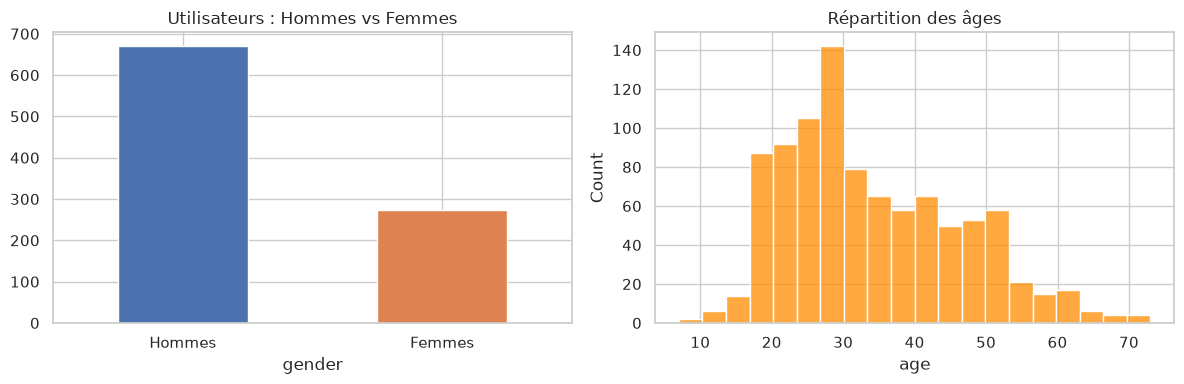

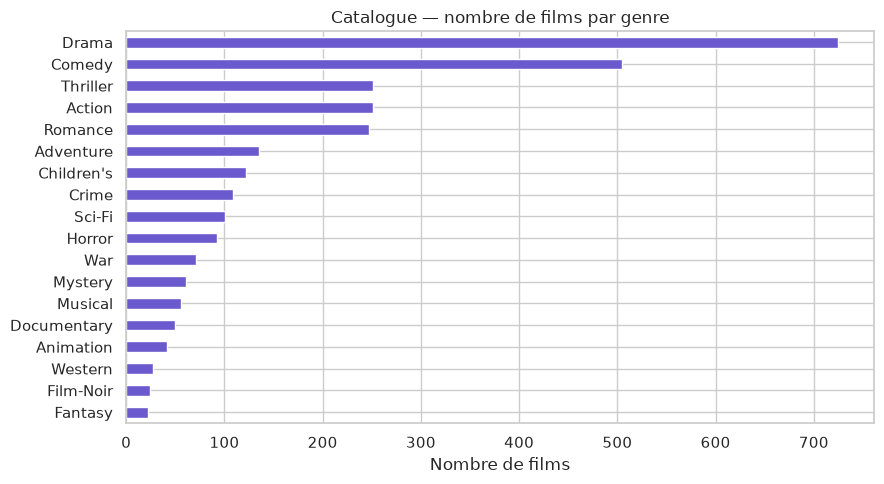

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
gender_counts = (
    users["gender"].map({"M": "Hommes", "F": "Femmes"})
    .value_counts()
    .reindex(["Hommes", "Femmes"])
)
gender_counts.plot(
    kind="bar",
    ax=axes[0],
    color=["#4C72B0", "#DD8452"],
)
axes[0].set_title("Nombre d'utilisateurs par sexe")
axes[0].set_xlabel("")
axes[0].set_ylabel("Effectif")
axes[0].tick_params(axis="x", rotation=0)
sns.histplot(users["age"], bins=20, ax=axes[1], color="darkorange")
axes[1].set_title("Répartition des âges")
plt.tight_layout()
plt.show()

catalogue_genres = (
    films["genres"].explode().value_counts().reindex(GENRES).fillna(0).astype(int)
)
catalogue_genres.sort_values().plot(kind="barh", figsize=(9, 5), color="slateblue")
plt.title("Catalogue — nombre de films par genre")
plt.xlabel("Nombre de films")
plt.tight_layout()
plt.show()


**Lecture**

- Panel déséquilibré : nettement plus d'**hommes** que de **femmes** ; public surtout jeune adulte.
- Le catalogue est dominé par Drama / Comedy : les parts de notes plus bas se lisent **relativement** à cette offre.


### 2. Corrélations entre genres

Les films ont souvent plusieurs genres. On regarde quels genres **apparaissent ensemble**
sur les mêmes films (corrélation de Pearson entre indicateurs 0/1 au niveau film).
Une forte corrélation positive = genres souvent associés dans le catalogue.


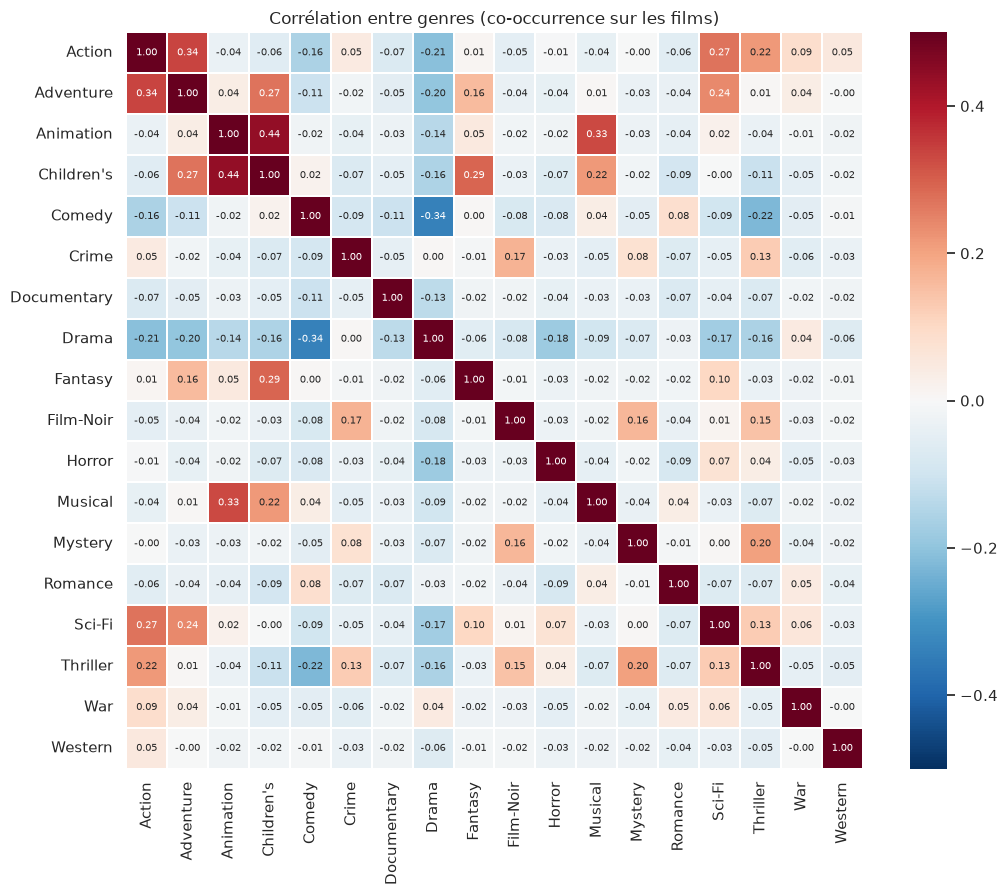

,genre_1,genre_2,corr
39,Animation,Children's,0.440
1,Action,Adventure,0.337
47,Animation,Musical,0.331
62,Children's,Fantasy,0.291
14,Action,Sci-Fi,0.273
21,Adventure,Children's,0.272
32,Adventure,Sci-Fi,0.238
15,Action,Thriller,0.218
65,Children's,Musical,0.216
231,Mystery,Thriller,0.204


,genre_1,genre_2,corr
319,Western,Romance,NaN
320,Western,Sci-Fi,NaN
321,Western,Thriller,NaN
322,Western,War,NaN
323,Western,Western,NaN


In [39]:
# Indicateurs 0/1 par film, puis corrélations entre genres
genre_flags = pd.DataFrame({
    g: films["genres"].map(lambda gs, genre=g: int(genre in gs)) for g in GENRES
})
corr_genres = genre_flags.corr(method="pearson")

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_genres,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    cmap="RdBu_r",
    center=0,
    vmin=-0.5,
    vmax=0.5,
    square=True,
    linewidths=0.3,
)
plt.title("Corrélation entre genres (co-occurrence sur les films)")
plt.tight_layout()
plt.show()

# Paires les plus liées (hors diagonale)
pairs = (
    corr_genres.where(np.triu(np.ones(corr_genres.shape), k=1).astype(bool))
    .stack()
    .rename("corr")
    .reset_index()
    .rename(columns={"level_0": "genre_1", "level_1": "genre_2"})
    .sort_values("corr", ascending=False)
)
display(pairs.head(10).round(3))
display(pairs.tail(5).round(3))


**Lecture — genres les plus corrélés**

Les corrélations les plus fortes (positives) regroupent des **familles de films** cohérentes :

- **Animation ↔ Children's (~0.44)** : la paire la plus liée. Beaucoup de films d'animation sont aussi tagués pour enfants.
- **Action ↔ Adventure (~0.34)** et **Action ↔ Sci-Fi (~0.27)** : bloc « spectacle / blockbuster ».
- **Animation ↔ Musical (~0.33)** et **Children's ↔ Fantasy (~0.29)** : prolongent la famille jeunesse / conte.

À l'opposé, de fortes corrélations **négatives** montrent des genres qui cohabitent peu :

- **Comedy ↔ Drama (~−0.34)** et **Comedy ↔ Thriller (~−0.22)** : comédie peu associée au drame / thriller.
- **Action ↔ Drama (~−0.21)** : action et drame se croisent moins souvent dans le catalogue.

**Conséquence pour la suite :** quand on dit qu'un groupe note plus d'Action, on traîne souvent aussi Adventure / Sci-Fi ; idem Animation avec Children's. Les profils âge/sexe doivent se lire avec ces bundles en tête, pas genre par genre comme s'ils étaient indépendants.


### 3. Parts de notes et notes moyennes selon le sexe

Deux lectures complémentaires :
1. **Parts** — quels genres sont le plus souvent notés (quantité) ;
2. **Notes moyennes** — comment ces genres sont notés (valeur 1–5).


,Femmes_%,Hommes_%,ecart_pts
Romance,22.76,18.32,4.44
Drama,42.77,38.90,3.87
Comedy,31.35,29.31,2.04
Children's,8.67,6.67,2.00
Musical,5.60,4.73,0.87
Animation,3.87,3.52,0.35
Fantasy,1.41,1.33,0.08
Documentary,0.73,0.77,-0.04
Mystery,5.11,5.29,-0.18
Film-Noir,1.50,1.82,-0.32


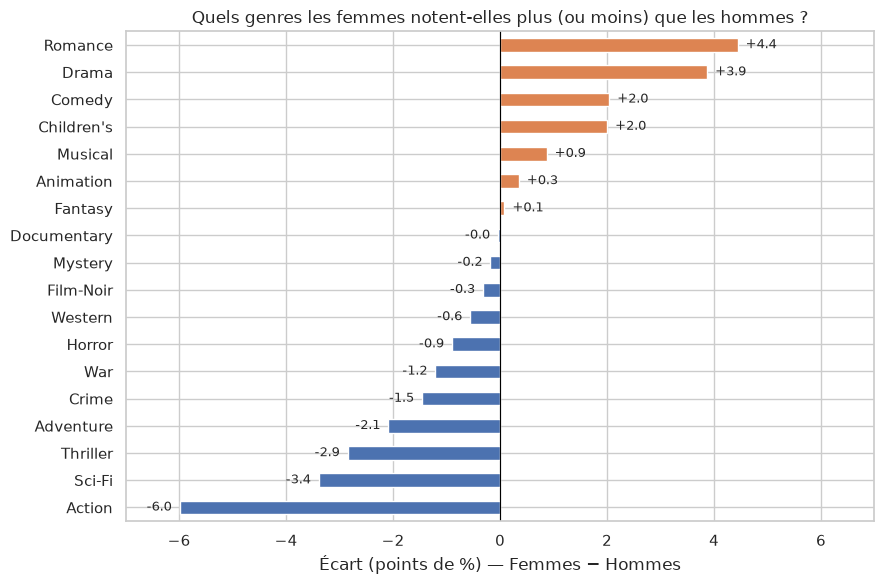

,Hommes,Femmes,ecart
Film-Noir,3.97,3.74,-0.23
War,3.83,3.78,-0.05
Drama,3.70,3.66,-0.04
Documentary,3.69,3.61,-0.08
Mystery,3.66,3.56,-0.10
Crime,3.65,3.56,-0.09
Western,3.64,3.51,-0.13
Romance,3.61,3.66,0.05
Sci-Fi,3.58,3.50,-0.08
Animation,3.56,3.63,0.07


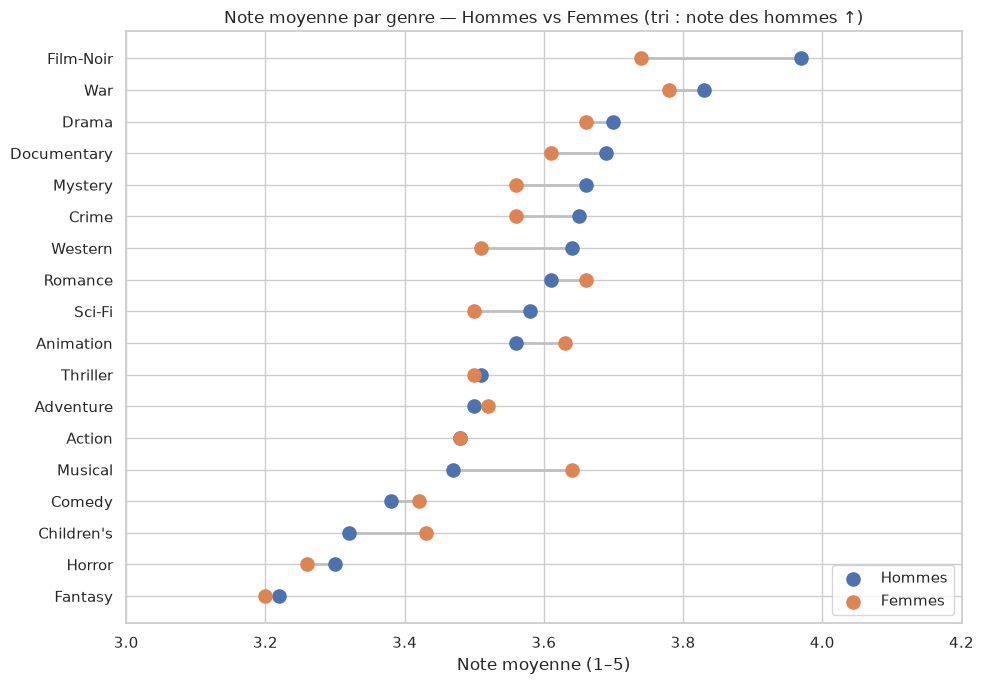

In [38]:
from matplotlib.patches import Patch

def preference_share(frame, group_col, genres=GENRES):
    """Part des notes d'un groupe qui touchent chaque genre (0–1), via la liste genres."""
    out = {}
    for key, sub in frame.groupby(group_col, observed=True):
        lists = sub["genres"]
        out[key] = {g: lists.map(lambda gs, genre=g: genre in gs).mean() for g in genres}
    return pd.DataFrame(out)


def mean_rating_by_genre(frame, group_col, genres=GENRES):
    """Note moyenne (1–5) des évaluations qui touchent chaque genre."""
    out = {}
    for key, sub in frame.groupby(group_col, observed=True):
        out[key] = {}
        for g in genres:
            mask = sub["genres"].map(lambda gs, genre=g: genre in gs)
            out[key][g] = sub.loc[mask, "rating"].mean()
    return pd.DataFrame(out)


color_femmes, color_hommes = "#DD8452", "#4C72B0"

# --- 1) Parts de notes (quantité) ---
pref_gender = preference_share(df, "gender")
tbl = pd.DataFrame({
    "Femmes_%": (100 * pref_gender["F"]).round(2),
    "Hommes_%": (100 * pref_gender["M"]).round(2),
})
tbl["ecart_pts"] = (tbl["Femmes_%"] - tbl["Hommes_%"]).round(2)
tbl = tbl.sort_values("ecart_pts", ascending=False)
display(tbl)

ecarts = tbl["ecart_pts"].sort_values()
lim = max(6.0, float(ecarts.abs().max()) + 1.5)
colors = [color_femmes if v > 0 else color_hommes for v in ecarts]

fig, ax = plt.subplots(figsize=(10, 6))
ecarts.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-lim, lim)
ax.set_xlabel("Écart de part de notes (points de %)")
ax.set_title("Parts de notes par genre : écart Femmes − Hommes")
ax.legend(
    handles=[
        Patch(facecolor=color_femmes, label="Femmes"),
        Patch(facecolor=color_hommes, label="Hommes"),
    ],
    loc="lower right",
    frameon=True,
)
for y, (genre, val) in enumerate(ecarts.items()):
    ax.text(
        val + (0.2 if val >= 0 else -0.2),
        y,
        f"{val:+.1f}",
        va="center",
        ha="left" if val >= 0 else "right",
        fontsize=9,
    )
plt.tight_layout()
plt.show()

# --- 2) Notes moyennes (valeur 1–5) ---
# SYNC_OK 2026-10-19 15:13:31
mean_gender = mean_rating_by_genre(df, "gender")
tbl_notes = pd.DataFrame({
    "Hommes": mean_gender["M"].round(2),
    "Femmes": mean_gender["F"].round(2),
})
tbl_notes["ecart"] = (tbl_notes["Femmes"] - tbl_notes["Hommes"]).round(2)

# Tri unique : note des hommes (croissant pour barh : bas = moins aimé, haut = plus aimé)
ordre = tbl_notes["Hommes"].sort_values(ascending=True).index.tolist()
tbl_notes = tbl_notes.loc[reversed(ordre)]
display(tbl_notes)

hommes_vals = tbl_notes.loc[ordre, "Hommes"].tolist()
femmes_vals = tbl_notes.loc[ordre, "Femmes"].tolist()
y_pos = list(range(len(ordre)))

# Dumbbell : une ligne par genre relie la note Hommes et la note Femmes
fig, ax = plt.subplots(figsize=(10, 7))
for y, h, f in zip(y_pos, hommes_vals, femmes_vals):
    ax.plot([h, f], [y, y], color="0.75", linewidth=2, zorder=1)
ax.scatter(hommes_vals, y_pos, s=90, color=color_hommes, zorder=3, label="Hommes")
ax.scatter(femmes_vals, y_pos, s=90, color=color_femmes, zorder=3, label="Femmes")
ax.set_yticks(y_pos)
ax.set_yticklabels(ordre)
ax.set_xlabel("Note moyenne (1–5)")
ax.set_xlim(3.0, 4.2)
ax.set_title("Note moyenne par genre — Hommes vs Femmes (tri : note des hommes ↑)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


**Lecture**

- Échelle en **points de %** : un écart de +4 signifie que ce genre occupe 4 points de plus
  dans les notes des femmes que dans celles des hommes.
- À droite (positif) : genres relativement plus notés par les **femmes** (souvent Romance, Drama).
- À gauche (négatif) : genres relativement plus notés par les **hommes** (souvent Action, Sci-Fi, Thriller).
- Drama et Comedy restent élevés **pour les deux** (offre dominante) : l'écart relativise mieux que la part brute.


### 4. Parts de notes par genre selon l'âge


,≤17,18-24,25-34,35-44,45-54,55+
Drama,33.4,36.4,38.6,41.0,46.6,47.2
Comedy,31.5,30.6,30.7,29.6,27.4,26.8
Action,29.4,28.5,26.6,23.9,22.0,19.2
Thriller,24.8,24.2,21.7,20.3,20.5,20.2
Romance,17.9,18.4,19.6,19.8,20.8,19.8
Adventure,15.3,14.4,14.4,14.1,11.5,10.5
Sci-Fi,13.2,13.3,13.9,12.4,10.6,8.5
War,7.9,7.9,9.4,10.1,10.8,10.8
Crime,8.3,8.9,7.8,7.3,8.0,8.4
Children's,10.7,7.4,7.2,8.3,5.3,5.3


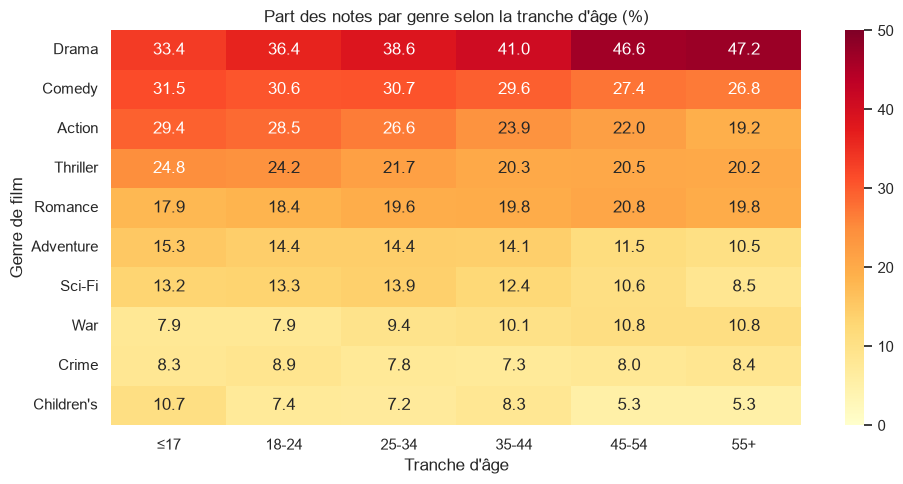

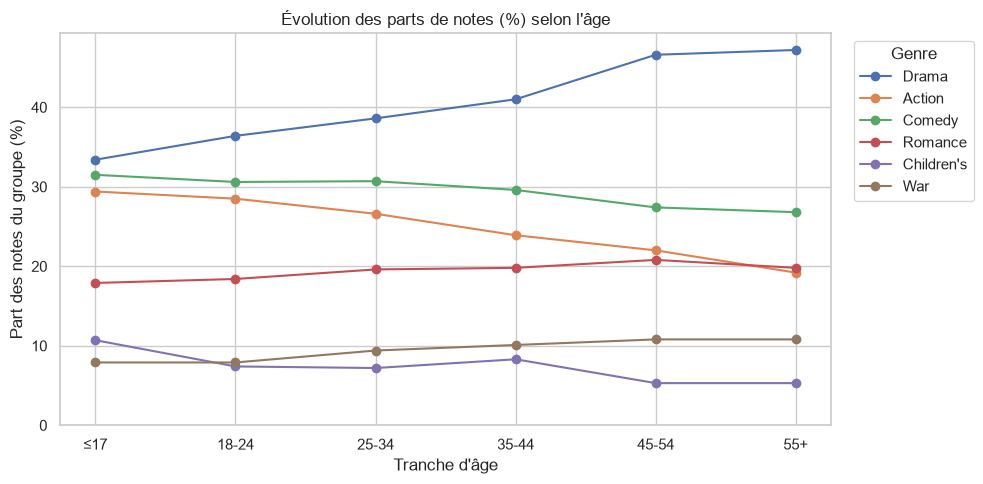

In [39]:
pref_age = preference_share(df, "age_bin")
# Parts en % pour une échelle lisible
pref_age_pct = (100 * pref_age).round(1)

top_genres = (
    df["genres"].explode().value_counts()
    .reindex(GENRES).fillna(0).astype(int)
    .sort_values(ascending=False)
    .head(10)
    .index.tolist()
)
pref_age_top = pref_age_pct.loc[top_genres]
display(pref_age_top)

plt.figure(figsize=(10, 5))
sns.heatmap(pref_age_top, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=50)
plt.title("Part des notes par genre selon la tranche d'âge (%)")
plt.xlabel("Tranche d'âge")
plt.ylabel("Genre de film")
plt.tight_layout()
plt.show()

focus = ["Drama", "Action", "Comedy", "Romance", "Children's", "War"]
pref_age_pct.loc[focus].T.plot(marker="o", figsize=(10, 5))
plt.title("Évolution des parts de notes (%) selon l'âge")
plt.ylabel("Part des notes du groupe (%)")
plt.xlabel("Tranche d'âge")
plt.ylim(0, None)
plt.legend(title="Genre", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


**Lecture**

- Heatmap (%): plus la case est chaude, plus le genre occupe une grande part des notes de la tranche.
- Avec l'âge, la part de **Drama** (et souvent War) augmente ; **Action** / **Comedy** / **Children's**
  baissent plutôt chez les plus âgés.
- Même indicateur que pour le sexe : structure des notes, pas satisfaction (note moyenne).


### 5. Synthèse

| Question | Constat (parts de notes) |
| --- | --- |
| Femmes vs hommes | Romance et Drama : parts plus élevées chez les femmes ; Action, Sci-Fi et Thriller : plus élevées chez les hommes (écarts en points de % sur le graphique). |
| Selon l'âge | La part de Drama augmente avec l'âge ; Action (et Children's chez les plus jeunes) est plus présente chez les plus jeunes. |
| Ce qu'on ne conclut pas | Pas de jugement sur la note moyenne ni de causalité âge/sexe → goût. |

→ **Étape suivante :** ce que ces constats ne permettent pas d'affirmer (biais, représentativité).


## Étape 4 — Qu'est-ce qui manque ?

L'étape 3 a répondu **de façon descriptive** à :
*quels genres sont proportionnellement les plus notés selon l'âge et le sexe ?*

Ici : ce que l'EDA **ne permet pas** de conclure — biais, limites, représentativité, causalité.

1. Biais
2. Limites des données
3. Représentativité (lien avec l'étape 3)
4. Causalité
5. Contrôles d'interprétation
6. Conclusion


### 1. Biais

- **Biais de sélection** : les utilisateurs et les films de MovieLens ne représentent ni toute la population ni l'ensemble du catalogue mondial.
- **Biais de participation** : on voit seulement ce qui est noté, pas ce qui est regardé sans note.
- **Biais de popularité / catalogue** : Drama et Comedy sont partout ; une part élevée de notes
  pour Drama reflète aussi l'offre, pas seulement un goût intrinsèque.


### 2. Limites des données

- Le jeu contient des notes, un profil utilisateur déclaré (âge, sexe, métier) et des genres, mais **pas** :
  le contexte de visionnage, les recommandations reçues, les goûts non exprimés, ni la raison d'une note.
- Les données sont **historiques** (1997–1998) : les comportements et l'offre de films ont évolué depuis.
- Certaines modalités sont **peu représentées** (métiers rares, genres peu notés) : une moyenne
  calculée sur peu d'observations doit être lue avec prudence.
- `video_release_date` est vide ; quelques `release_date` / `release_year` manquent.


### 3. Représentativité (lien avec l'étape 3)

Les parts de notes décrivent **ce jeu MovieLens**, pas tous les spectateurs.

- Les **hommes** sont sur-représentés : leurs profils (plus Action / Sci-Fi) pèsent plus dans le global.
- Les tranches d'âge n'ont pas les mêmes effectifs : une forte part Drama chez les 55+ repose sur moins d'utilisateurs.
- Un genre « plus noté » ≠ un genre « mieux noté ».


### 4. Causalité

Observer qu'un groupe note plus souvent un genre **ne prouve pas** que l'âge ou le sexe
*causent* ce profil de notes. L'offre de films, les recommandations, la période (1997–1998) ou d'autres
facteurs non observés peuvent intervenir. L'EDA reste descriptive.


### 5. Contrôles d'interprétation

Quelques indicateurs pour rappeler l'échelle du jeu et la fragilité des petits effectifs.


Métiers les **moins** et les **plus** représentés (par volume de notes) :


In [40]:
print(f"Utilisateurs observés : {df['user_id'].nunique():,}")
print(f"Films observés        : {df['item_id'].nunique():,}")
print(f"Notes observées       : {len(df):,}")

notes_par_film = df.groupby("item_id").size()
notes_par_user = df.groupby("user_id").size()
print(f"\nFilms avec < 10 notes     : {(notes_par_film < 10).sum():,}")
print(f"Film le plus noté         : {notes_par_film.max():,} notes")
print(f"Utilisateur le plus actif : {notes_par_user.max():,} notes")

occ = (
    df.groupby("occupation")
      .agg(
          n_notes=("rating", "size"),
          note_moyenne=("rating", "mean"),
          n_users=("user_id", "nunique"),
      )
      .sort_values("n_notes")
)

display(occ.head(5).round(3))
display(occ.tail(5).round(3))


Utilisateurs observés : 943
Films observés        : 1,680
Notes observées       : 99,990

Films avec < 10 notes     : 528
Film le plus noté         : 583 notes
Utilisateur le plus actif : 737 notes


,n_notes,note_moyenne,n_users
occupation,,,
homemaker,299,3.301,7
doctor,540,3.689,7
salesman,856,3.583,12
none,900,3.778,9
lawyer,1345,3.735,12


,n_notes,note_moyenne,n_users
occupation,,,
programmer,7800,3.568,66
engineer,8174,3.541,67
educator,9441,3.671,95
other,10662,3.552,105
student,21956,3.515,196


**Biais de représentativité socioprofessionnelle** : Le jeu de données de 1997-1998 est massivement dominé par des étudiants, des enseignants/éducateurs, des ingénieurs et des développeurs/programmeurs.

**Stabilité des notes moyennes** : La note moyenne varie très peu selon le métier (elle reste comprise entre 3,3 et 3,8). L'élément discriminant majeur réside dans le volume d'activité (n_notes), reflétant la surreprésentation des profils techniques et académiques sur le Web à la fin des années 1990.

### 6. Conclusion

- **Ce que l'EDA montre :** 
L'activité de notation varie significativement selon le sexe et l'âge. Les écarts mesurés en points de pourcentage (pts) révèlent une sur-appétence des femmes pour le Drame et la Romance (+4.4pts), tandis que les hommes privilégient l'Action (-6.0pts), la Science-Fiction et le Thriller.

Avec l'avancée en âge, on observe une dérive progressive des évaluations : la part accordée aux Drames augmente, au détriment des films d'Action.

L'exclusion du genre Unknown et la conversion des données brutes en parts relatives (%) ont permis de neutraliser les déséquilibres de volume et d'isoler la véritable préférence relative de chaque groupe.

- **Ce qu'elle ne montre pas :**
L'analyse mesure le volume d'activité par genre (l'intérêt à évaluer) et non une note moyenne de satisfaction, cette dernière restant quasi constante (environ 3.5/5) entre les groupes.

L'EDA décrit des corrélations statistiques au sein de l'échantillon, mais ne prouve aucun lien de causalité direct entre le sexe/l'âge et les goûts cinématographiques.

- **Biais à garder en tête :** panel hommes sur-représentés (75%) et dominée par les milieux académiques et techniques (étudiants, enseignants, ingénieurs)représentatifs des usagers du Web en 1997-1998,
et l'offre Drama(40%) / Comedy (30%) sur-dominent naturellement l'ensemble de la base en raison de la composition de l'offre de l'époquedonnées 1997–1998.

- Les résultats restent **descriptifs** et liés à MovieLens 100k (effectifs faibles = prudence).
